# Workshop 3-2: Logistic regression (class imbalance)

**Real-life problem:** Catching card fraud when almost every transaction is legitimate. Accuracy hides the failure.

**My twist:** Swap the workshop's simulated data for 284,807 real card transactions (0.17% fraud). Keep its class weights and add the weight grid the PDF describes but doesn't show. Score with precision, recall and PR-AUC, then pick the alert line by business cost: a missed fraud costs €100 and a false alarm €5 (change these). Finally, let a missed fraud cost what was actually stolen.

**Done when:** A table of total cost for plain vs class-weighted logistic regression at their best thresholds, and a one-line recommendation.

*Baseline = the lecturer's workshop code (unmodified copy in `_baseline/`). Everything below the line starts as that baseline; edit it.*

---

## Part A: class imbalance with logistic regression (the lecturer's baseline)

A balanced dataset, then a 1%-minority dataset, then class weights, all scored with ROC AUC. Left as is.

Counter({np.int64(0): 5000, np.int64(1): 5000})


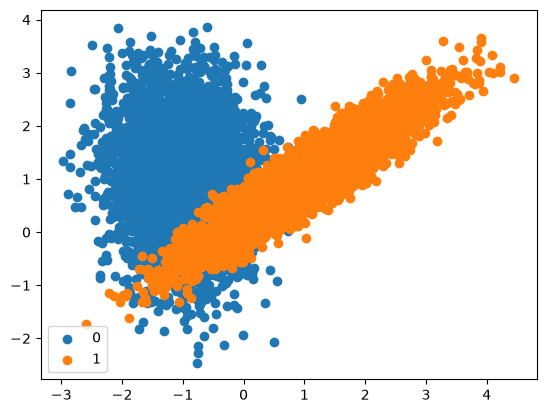

In [1]:
	# Generate and plot a synthetic balanced classification dataset
from collections import Counter
from sklearn.datasets import make_classification
from matplotlib import pyplot
from numpy import where
# define dataset
X, y = make_classification(n_samples=10000, n_features=2, n_redundant=0,
  n_clusters_per_class=1, weights=[0.5], flip_y=0, random_state=2)
# summarize class distribution
counter = Counter(y)
print(counter)
# scatter plot of examples by class label
for label, _ in counter.items():
  row_ix = where(y == label)[0]
  pyplot.scatter(X[row_ix, 0], X[row_ix, 1], label=str(label))
pyplot.legend()
pyplot.show()

In [2]:
	# fit a logistic regression model on an balanced classification dataset
from numpy import mean
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.linear_model import LogisticRegression

# define model
model = LogisticRegression(solver='lbfgs')
# define evaluation procedure
cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=1)
# evaluate model
scores = cross_val_score(model, X, y, scoring='roc_auc', cv=cv, n_jobs=-1)
# summarize performance
print('Mean ROC AUC: %.3f' % mean(scores))

Mean ROC AUC: 0.983


In [3]:
# CLASS IMBALANCE

Counter({np.int64(0): 9900, np.int64(1): 100})


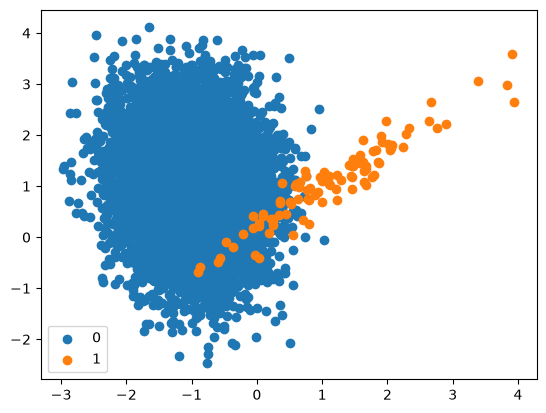

In [4]:
# Generate and plot a synthetic imbalanced classification dataset
from collections import Counter
from sklearn.datasets import make_classification
from matplotlib import pyplot
from numpy import where

# define dataset
X, y = make_classification(n_samples=10000, n_features=2, n_redundant=0,
  n_clusters_per_class=1, weights=[0.99], flip_y=0, random_state=2)
# summarize class distribution
counter = Counter(y)
print(counter)
# scatter plot of examples by class label
for label, _ in counter.items():
  row_ix = where(y == label)[0]
  pyplot.scatter(X[row_ix, 0], X[row_ix, 1], label=str(label))
pyplot.legend()
pyplot.show()

In [5]:
# fit a logistic regression model on an imbalanced classification dataset
from numpy import mean
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.linear_model import LogisticRegression

# define model
weights = {0:0.01, 1:0.99}
model = LogisticRegression(solver='lbfgs',class_weight=weights)
#model = LogisticRegression(solver='lbfgs', class_weight='balanced')
# define evaluation procedure
cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=1)
# evaluate model
scores = cross_val_score(model, X, y, scoring='roc_auc', cv=cv, n_jobs=-1)
# summarize performance
print('Mean ROC AUC: %.3f' % mean(scores))

Mean ROC AUC: 0.989


---
## Part B: real life: catching card fraud on real transactions

**Problem:** a card issuer sees thousands of transactions a minute, and a tiny share are fraud. Each fraud it misses costs money; each legitimate transaction it wrongly flags costs a call to an annoyed customer. **Where should the alert line be?**

**Data:** 284,807 real card transactions by European cardholders over two days in September 2013, 492 of them fraud (0.17%, about 6 times rarer than the workshop's 1%). They were collected by Worldline and the Machine Learning Group of the Université Libre de Bruxelles ([OpenML 1597](https://www.openml.org/d/1597); Dal Pozzolo, Caelen, Johnson and Bontempi, *Calibrating Probability with Undersampling for Unbalanced Classification*, IEEE CIDM 2015). For confidentiality, the bank's own features are hidden behind 28 anonymous numbers (V1 to V28, the output of a PCA). Only the amount is left as it was. The data downloads once (about 80 MB) and is cached outside the repo.

**My cost assumptions (change them):** a missed fraud costs **€100** (the real average fraud here is about €120), and a false alarm costs **€5**. Section 4 drops the flat €100 and uses each transaction's real amount. The dataset doesn't name its currency; I assume euros.

**Plan:** show why accuracy is the wrong score → compare class-weighted models → pick the alert line by cost → check how it changes if the € figures change → let the line depend on the amount.

In [6]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, average_precision_score, accuracy_score, precision_score, recall_score
warnings.filterwarnings('ignore')   # some warnings print file paths from your computer

cards = fetch_openml(data_id=1597, as_frame=True, parser='auto').frame   # downloads once (about 80 MB), cached in ~/scikit_learn_data
n_all = len(cards)
# OpenML's copy has no time column, so 9,144 rows are exact repeats. Keep one of each, so the same
# transaction can't sit in both the training and the test folds.
cards = cards.drop_duplicates().reset_index(drop=True)
X = cards.drop(columns='Class').to_numpy()
y = cards['Class'].astype(int).to_numpy()
amount = cards['Amount'].to_numpy()

COST_MISS = 100        # € lost per fraud we fail to flag
COST_FALSE_ALARM = 5   # € per legitimate transaction we wrongly flag
# finer steps near 0 and 1, where the cheapest lines turn out to be
thresholds = np.unique(np.round(np.concatenate([np.arange(0.001, 0.01, 0.001), np.arange(0.01, 0.99, 0.01),
                                                np.arange(0.99, 1.0, 0.001)]), 3))

def total_cost(y_true, p, t, miss=COST_MISS, alarm=COST_FALSE_ALARM):
    flagged = p >= t
    return miss * ((~flagged) & (y_true == 1)).sum() + alarm * (flagged & (y_true == 0)).sum()

print(f'{n_all:,} transactions; {n_all - len(y):,} exact repeats removed, leaving {len(y):,}')
print(f'{y.sum()} frauds ({y.mean():.2%}); a fraud is €{np.median(amount[y == 1]):.2f} at the median, '
      f'€{amount[y == 1].mean():.0f} on average, €{amount[y == 1].sum():,.0f} in all')
print(f'cost of doing nothing:       €{COST_MISS * y.sum():,}')
print(f'cost of flagging everything: €{COST_FALSE_ALARM * (y == 0).sum():,}')

284,807 transactions; 9,144 exact repeats removed, leaving 275,663
473 frauds (0.17%); a fraud is €9.82 at the median, €124 on average, €58,591 in all
cost of doing nothing:       €47,300
cost of flagging everything: €1,375,950


### 1. Accuracy hides the failure
Each model predicts every transaction it did **not** train on (10-fold cross-validation), so the numbers are not flattered. The amount is in euros while the 28 anonymous numbers are small, so each model first scales them alike (fitted on its training folds only). The class weights are the workshop's idea: `balanced`, the workshop's `{0: 0.01, 1: 0.99}`, and a small grid of weights on the fraud class (the "grid search" the PDF describes). Scores below use the default alert line of 0.5.

In [7]:
models = {
    'plain':                 dict(),
    'balanced':              dict(class_weight='balanced'),
    'workshop {0:.01,1:.99}': dict(class_weight={0: 0.01, 1: 0.99}),
}
for w in (2, 5, 10, 25, 50):                                  # grid over the fraud-class weight
    models[f'fraud weight {w}'] = dict(class_weight={0: 1, 1: w})

def model(**kw):
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, **kw))

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=1)
proba = {name: cross_val_predict(model(**kw), X, y, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
         for name, kw in models.items()}

rows = []
for name, p in proba.items():
    rows.append({'model': name,
                 'accuracy': accuracy_score(y, p >= 0.5),
                 'frauds caught (recall)': recall_score(y, p >= 0.5),
                 'alerts that are real (precision)': precision_score(y, p >= 0.5, zero_division=0),
                 'false alarms': int(((p >= 0.5) & (y == 0)).sum()),
                 'ROC AUC': roc_auc_score(y, p),
                 'PR-AUC': average_precision_score(y, p),
                 'cost at 0.5 (€)': total_cost(y, p, 0.5)})
at_half = pd.DataFrame(rows).set_index('model')
at_half.round(4)

,accuracy,frauds caught (recall),alerts that are real (precision),false alarms,ROC AUC,PR-AUC,cost at 0.5 (€)
model,,,,,,,
plain,0.9991,0.6004,0.8606,46,0.9734,0.7399,19130
balanced,0.9763,0.9070,0.0621,6483,0.9781,0.7169,36815
"workshop {0:.01,1:.99}",0.9959,0.8605,0.2746,1075,0.9785,0.7357,11975
fraud weight 2,0.9992,0.7125,0.8160,76,0.9765,0.7463,13980
fraud weight 5,0.9993,0.7844,0.7944,96,0.9775,0.7475,10680
fraud weight 10,0.9992,0.8034,0.7615,119,0.9777,0.7462,9895
fraud weight 25,0.9989,0.8288,0.6405,220,0.9781,0.7433,9200
fraud weight 50,0.9982,0.8457,0.4854,424,0.9783,0.7398,9420


- **Accuracy is useless here.** Every model scores between 97.6% and 99.9%, and simply saying "never fraud" would score 99.83%. Plain logistic regression has among the best accuracy (99.91%), yet it misses 40% of the fraud.
- **Class weights trade false alarms for catches.** `balanced` catches 91% of the fraud, but only 6% of its alerts are real: 6,483 false alarms to find 429 frauds. Moderate weights (5 to 25) sit in between.
- **ROC AUC barely moves** (0.973 to 0.978), and neither does PR-AUC (0.72 to 0.75). The models rank transactions about equally well; they differ in where the 0.5 line falls.
- **Money is the honest score.** Doing nothing costs €47,300. At the default 0.5 line the models cost between €9,200 and €36,800. The next step is to stop using 0.5.

### 2. Pick the alert line by cost
For each model, the total cost at every possible threshold. A model flags a transaction when its fraud probability is at least the threshold. The horizontal axis stretches both ends, because that is where the cheapest lines are.

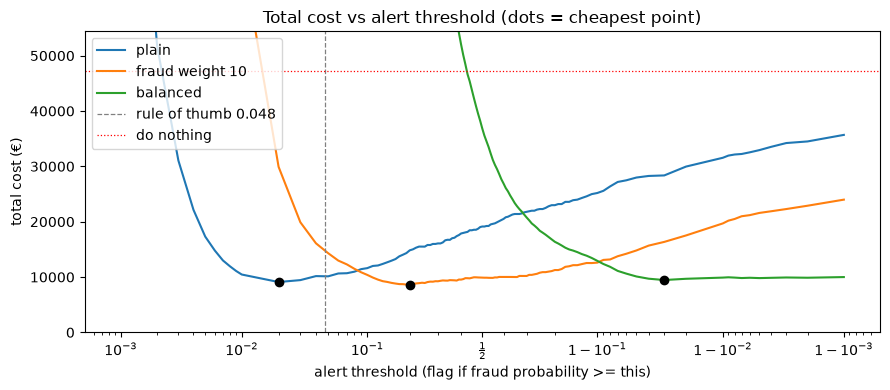

In [8]:
curves = {name: [total_cost(y, p, t) for t in thresholds] for name, p in proba.items()}
theory_t = COST_FALSE_ALARM / (COST_FALSE_ALARM + COST_MISS)    # rule of thumb for a calibrated model

fig, ax = plt.subplots(figsize=(9, 4))
for name in ['plain', 'fraud weight 10', 'balanced']:
    c = np.array(curves[name])
    ax.plot(thresholds, c, label=name)
    ax.plot(thresholds[c.argmin()], c.min(), 'ko')
ax.axvline(theory_t, color='grey', ls='--', lw=0.9, label=f'rule of thumb {theory_t:.3f}')
ax.axhline(COST_MISS * y.sum(), color='r', ls=':', lw=0.9, label='do nothing')
ax.set_xscale('logit'); ax.set_ylim(0, COST_MISS * y.sum() * 1.15)
ax.set_xlabel('alert threshold (flag if fraud probability >= this)'); ax.set_ylabel('total cost (€)')
ax.set_title('Total cost vs alert threshold (dots = cheapest point)')
ax.legend(); plt.tight_layout(); plt.show()

Every model has a cheapest point, at very different thresholds. Class weights don't make a model smarter; mostly they move the line.

Picking the cheapest point on the same data it is measured on is slightly flattering, so the next cell is more honest: choose the threshold on one random half of the transactions and score it on the other half (and vice versa), repeated over 20 different splits.

In [9]:
def honest_cost(p, miss=COST_MISS, alarm=COST_FALSE_ALARM, repeats=20):
    totals = []
    for seed in range(repeats):
        total = 0
        for pick, score in StratifiedKFold(2, shuffle=True, random_state=seed).split(p, y):
            t = thresholds[np.argmin([total_cost(y[pick], p[pick], t, miss, alarm) for t in thresholds])]
            total += total_cost(y[score], p[score], t, miss, alarm)
        totals.append(total)
    return np.mean(totals), np.std(totals)

rows = []
for name, p in proba.items():
    c = np.array(curves[name]); mean, sd = honest_cost(p)
    best_t = thresholds[c.argmin()]
    rows.append({'model': name,
                 'cost at 0.5 (€)': total_cost(y, p, 0.5),
                 'cheapest threshold': best_t,
                 'flagged there (%)': round((p >= best_t).mean() * 100, 2),
                 'honest cost (€)': round(mean),
                 'spread across splits (€)': round(sd),
                 f'cost at rule-of-thumb {theory_t:.3f} (€)': total_cost(y, p, theory_t)})
costs = pd.DataFrame(rows).set_index('model')
costs

,cost at 0.5 (€),cheapest threshold,flagged there (%),honest cost (€),spread across splits (€),cost at rule-of-thumb 0.048 (€)
model,,,,,,
plain,19130,0.02,0.25,9181,164,10060
balanced,36815,0.97,0.28,9716,215,549295
"workshop {0:.01,1:.99}",11975,0.74,0.26,9477,212,130615
fraud weight 2,13980,0.05,0.22,8916,198,8810
fraud weight 5,10680,0.09,0.25,8791,82,10415
fraud weight 10,9895,0.20,0.24,8658,163,14750
fraud weight 25,9200,0.41,0.24,8790,90,30115
fraud weight 50,9420,0.60,0.25,9082,262,63455


- **Tuning the line is where the money is.** Plain logistic regression goes from €19,130 at 0.5 to about €9,200, a 52% cut and 81% below doing nothing (€47,300), while flagging only a quarter of a percent of transactions. No new model was needed.
- **On real data a modest class weight helps, a little.** A fraud weight of 10 lands at about €8,660, about €520 (6%) cheaper than plain, around three times the split-to-split spread. Heavy weights (`balanced` and the workshop's) end up worse than plain. On the simulated data every variant tied.
- **The rule of thumb misfires, even for the plain model:** €10,060 at 4.8%, against €9,100 at its cheapest line (2%). The rule assumes that a "5% fraud chance" really means 5%. The next cell checks that. (A weight of 2 happens to land near the best at the rule of thumb, €8,810, because its probabilities run slightly higher.)

In [10]:
# Does "a 5% fraud chance" really mean 5%? Group the plain model's predictions into bands and compare.
p = proba['plain']
bands = pd.cut(p, [0, 0.001, 0.01, 0.05, 0.2, 0.5, 0.9, 1], include_lowest=True)
check = pd.DataFrame({'predicted': p, 'fraud': y}).groupby(bands, observed=True).agg(
    transactions=('fraud', 'size'), model_says=('predicted', 'mean'), really_fraud=('fraud', 'mean'))
check.index.name = 'predicted fraud chance'
check[['model_says', 'really_fraud']] = (check[['model_says', 'really_fraud']] * 100).round(2)
check.rename(columns={'model_says': 'model says (average %)', 'really_fraud': 'really fraud (%)'})

,transactions,model says (average %),really fraud (%)
predicted fraud chance,,,
"(-0.001, 0.001]",249617,0.03,0.02
"(0.001, 0.01]",24952,0.22,0.13
"(0.01, 0.05]",569,1.83,4.22
"(0.05, 0.2]",111,10.62,45.05
"(0.2, 0.5]",84,34.78,53.57
"(0.5, 0.9]",70,70.44,87.14
"(0.9, 1.0]",260,98.67,85.77


**The plain model's probabilities are off on real data.** Where it says 5% to 20% (10.6% on average), 45% of transactions are really fraud. Where it says 1% to 5%, 4% are. It is too timid in the middle, so the rule of thumb puts the line too high and misses frauds it could have caught. At the very top it is too sure: it says 99%, and 86% are fraud. On the simulated data the probabilities could be taken at face value; real data is messier. Picking the line on past transactions, as in the table above, works whether or not the probabilities can be trusted.

### 3. What if the € figures are wrong?
The threshold depends entirely on the two cost assumptions, which in a real company come from finance or risk, not from the data scientist. For plain logistic regression at the rule-of-thumb threshold (slightly off, as just shown, but it shows the trade-off):

In [11]:
p = proba['plain']
rows = []
for miss in (20, 50, 100, 500, 1000):
    t = COST_FALSE_ALARM / (COST_FALSE_ALARM + miss)
    flagged = p >= t
    rows.append({'missed fraud costs (€)': miss,
                 'alert threshold': round(t, 3),
                 'transactions flagged (%)': round(flagged.mean() * 100, 2),
                 'alerts that are real fraud (%)': round(precision_score(y, flagged) * 100),
                 'frauds caught (%)': round(recall_score(y, flagged) * 100),
                 'total cost (€)': total_cost(y, p, t, miss=miss),
                 'doing nothing (€)': miss * y.sum()})
pd.DataFrame(rows).set_index('missed fraud costs (€)')

,alert threshold,transactions flagged (%),alerts that are real fraud (%),frauds caught (%),total cost (€),doing nothing (€)
missed fraud costs (€),,,,,,
20,0.200,0.15,79,70,3305,9460
50,0.091,0.17,78,77,5975,23650
100,0.048,0.19,71,80,10060,47300
500,0.010,0.40,36,85,38510,236500
1000,0.005,0.95,16,87,74105,473000


- **The line follows the cost of a miss.** From €20 to €1,000 per missed fraud, the line drops from 20% to 0.5%. Flagged transactions rise from 0.15% to 0.95%, and the share of alerts that are real falls from 79% to 16%.
- **But catches rise slowly:** from 70% to 87% of frauds. The last frauds are the hardest, and each one costs many more false alarms.

### 4. A missed fraud costs what was stolen
The flat €100 was a stand-in. This data has the real amount of every transaction, and the dataset's authors suggest using it for exactly this. Now a missed fraud costs its amount, and a false alarm still costs €5. Three ways to set the line for plain logistic regression:
- **One line, rule of thumb:** the 4.8% from section 2.
- **One line, the best one:** the cheapest single threshold, picked with hindsight (so flattering).
- **A line per transaction:** flag when the expected loss is bigger than the cost of a call, that is, when the fraud chance is at least `5 / (5 + amount)`. It is the rule of thumb with each transaction's own amount: a €1,000 transaction is flagged at a 0.5% fraud chance, a €100 one at 4.8%, a €10 one at 33%, and a €1 one only above 83%. Nothing is tuned.

In [12]:
p = proba['plain']

def money_cost(flagged):
    return amount[(~flagged) & (y == 1)].sum() + COST_FALSE_ALARM * (flagged & (y == 0)).sum()

def describe(flagged):
    return {'total cost (€)': round(money_cost(flagged)),
            'transactions flagged (%)': flagged.mean() * 100,
            'alerts that are real fraud (%)': precision_score(y, flagged, zero_division=0) * 100,
            'frauds caught (%)': recall_score(y, flagged) * 100,
            'stolen money caught (%)': amount[flagged & (y == 1)].sum() / amount[y == 1].sum() * 100}

best_single = thresholds[np.argmin([money_cost(p >= t) for t in thresholds])]
rules = {'do nothing': np.zeros(len(y), bool),
         f'one line, rule of thumb ({theory_t:.3f})': p >= theory_t,
         f'one line, best with hindsight ({best_single})': p >= best_single,
         'a line per transaction: 5 / (5 + amount)': p >= COST_FALSE_ALARM / (COST_FALSE_ALARM + amount)}
print(f'{((amount == 0) & (y == 1)).sum()} of the frauds are for €0')
pd.DataFrame({name: describe(flagged) for name, flagged in rules.items()}).T.round(2)

25 of the frauds are for €0


,total cost (€),transactions flagged (%),alerts that are real fraud (%),frauds caught (%),stolen money caught (%)
do nothing,58591.0,0.00,0.00,0.00,0.00
"one line, rule of thumb (0.048)",16462.0,0.19,71.43,80.34,73.20
"one line, best with hindsight (0.03)",15540.0,0.22,65.05,82.24,75.26
a line per transaction: 5 / (5 + amount),14863.0,0.23,48.58,64.90,77.41


- **A line per transaction loses the least money:** €14,860, against €16,460 for the rule-of-thumb line and €15,540 for the best single line, even though that one was picked with hindsight. Doing nothing loses €58,590.
- **It catches fewer frauds but more of the money:** 65% of frauds, against 80% to 82%, but 77% of the stolen money, against 73% to 75%. It stops chasing small frauds, where a €5 call costs more than the fraud is likely to lose, and looks harder at big ones.
- **Fewer of its alerts are real** (49%, against 65% to 71%), because it flags big transactions on weak evidence. That is the right call when an alert costs €5 and a missed big fraud costs hundreds.
- **It never flags the 25 frauds for €0.** They cost nothing here, but a €0 transaction is often a fraudster checking that a stolen card works, so a separate rule should catch them.
- **The score a team is judged on changes the answer:** "frauds caught" picks the single line; "money saved" picks a line per transaction.

### Recommendation

**Set the alert line from the costs, never at 0.5, and pick it on past transactions instead of trusting the rule of thumb.** On 275,663 real transactions, that takes plain logistic regression from €19,130 to about €9,200 (doing nothing: €47,300) while flagging a quarter of a percent of transactions. A modest fraud weight (10) saves a further 6%. **If a missed fraud costs what was stolen, give each transaction its own line, `€5 / (€5 + amount)`:** it loses about €14,900 against €58,600 for doing nothing, less than any single line. Re-set the lines whenever the € figures change, and catch €0 card checks with a separate rule.

**Caveats:** two days of 2013 transactions from one European card issuer. The features are anonymous, so there is no telling what the model relies on. Transactions are shuffled into folds, so the model partly learns from transactions that came after the ones it is tested on; a real system only learns from the past. The €5 and €100 are my assumptions, and the amount leaves out fees, chargebacks and the customer's trust. The probabilities are miscalibrated, so calibrating them first would probably make both kinds of line cheaper.